In [1]:
import requests, pandas as pd

url = "https://api.frankfurter.dev/v1/2015-01-01.."
params = {"base": "CAD", "symbols": "USD,EUR,GBP,CHF,TRY,JPY,THB,CNY,AUD,NZD,ZAR"}
data = requests.get(url, params=params).json()

df = pd.DataFrame(data["rates"]).T
df.index = pd.to_datetime(df.index)
print(df.shape)
print(df.isna().sum())      # missing value check
print(df.head(), df.tail())  # start and end of dataset

df.to_csv("fx_rates_cad.csv")


(3027, 11)
AUD    0
CHF    0
CNY    0
EUR    0
GBP    0
JPY    0
NZD    0
THB    0
TRY    0
USD    0
ZAR    0
dtype: int64
               AUD      CHF     CNY      EUR      GBP     JPY     NZD     THB  \
2014-12-31  1.0545  0.85501  5.3586  0.71109  0.55386  103.27  1.1040  28.379   
2015-01-02  1.0549  0.85450  5.3137  0.71078  0.55441  103.21  1.1095  28.211   
2015-01-05  1.0509  0.85578  5.2782  0.71220  0.55744  101.84  1.1050  27.987   
2015-01-06  1.0447  0.85729  5.2820  0.71357  0.55958  101.11  1.0973  27.987   
2015-01-07  1.0474  0.85817  5.2524  0.71449  0.55895  100.86  1.0914  27.802   

               TRY      USD     ZAR  
2014-12-31  2.0138  0.86333  9.9803  
2015-01-02  2.0138  0.85600  9.9819  
2015-01-05  1.9848  0.84859  9.9522  
2015-01-06  1.9789  0.85015  9.9737  
2015-01-07  1.9682  0.84531  9.9020                  AUD      CHF     CNY      EUR      GBP     JPY     NZD     THB  \
2026-10-21  1.0122  0.58660  4.7531  0.63375  0.53124  112.40  1.2507  23.904   


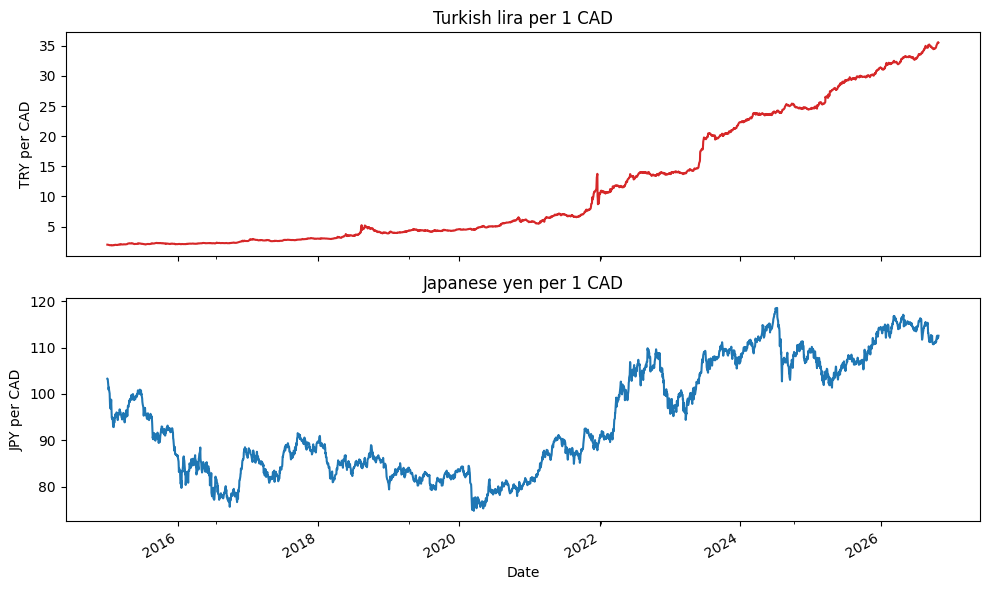

Days with unusually large moves: 84
AUD   2025-04-04
CHF   2015-01-15
CNY   2015-08-11
EUR   2015-01-23
GBP   2016-06-24
JPY   2016-06-24
NZD   2020-03-24
THB   2015-01-22
TRY   2021-12-21
USD   2016-03-17
ZAR   2022-12-01
dtype: datetime64[ns]
AUD    0.033247
CHF    0.129593
CNY    0.022986
EUR    0.029840
GBP    0.063417
JPY    0.051182
NZD    0.026861
THB    0.021992
TRY    0.267429
USD    0.029064
ZAR    0.051906
dtype: float64


In [2]:
import matplotlib.pyplot as plt

# 1. Line charts (separate panels, since the scales are very different)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

df["TRY"].plot(ax=axes[0], color="tab:red")
axes[0].set_title("Turkish lira per 1 CAD")
axes[0].set_ylabel("TRY per CAD")

df["JPY"].plot(ax=axes[1], color="tab:blue")
axes[1].set_title("Japanese yen per 1 CAD")
axes[1].set_ylabel("JPY per CAD")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

# 2. Flag odd spikes: daily % change beyond 4 standard deviations
returns = df.pct_change().dropna()
threshold = 4 * returns.std()
spikes = returns[(returns.abs() > threshold).any(axis=1)]

print("Days with unusually large moves:", len(spikes))
print(returns.abs().idxmax())   # date of each currency's biggest daily move
print(returns.abs().max())      # size of that biggest move